# MAPPO vs LOLA — Comparaison sur le modèle Common Pool (§5)

**MAPPO** (Multi-Agent PPO) : entraînement centralisé (critic voit l'état global), exécution décentralisée.

**LOLA** (Learning with Opponent-Aware Learning) : chaque agent simule un pas de gradient des autres avant de se mettre à jour — il optimise dans le monde *post-apprentissage* des autres.

Environnement : §2–§5 de `equations.md`. Récompense : formulation sigmoid §5.1.

In [3]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical
from collections import defaultdict, deque
import matplotlib.pyplot as plt
import copy, warnings
from tqdm.notebook import tqdm
warnings.filterwarnings('ignore')

N_EPS   = 100
N_SEEDS = 3
SEEDS   = [42, 123, 7, 17, 99, 256, 314, 512, 777, 1337]

BASE_CONFIG = dict(
    N=6, E0=500, regen_rate=1.0,
    m=10, tau=0.5, lam=5.0,
    gamma_hist=0.9, max_steps=2000
)

CONDITIONS = [
    {'see_emotions': True,  'alpha': 0.5, 'label': 'emo, α=0.5'},
    {'see_emotions': True,  'alpha': 0.0, 'label': 'emo, α=0.0'},
    {'see_emotions': False, 'alpha': 0.5, 'label': 'aveugle, α=0.5'},
    {'see_emotions': False, 'alpha': 0.0, 'label': 'aveugle, α=0.0'},
]

COND_STYLE = {
    'emo, α=0.5':     {'color': '#2ecc71', 'ls': '-'},
    'emo, α=0.0':     {'color': '#27ae60', 'ls': '--'},
    'aveugle, α=0.5': {'color': '#e67e22', 'ls': '-'},
    'aveugle, α=0.0': {'color': '#e74c3c', 'ls': '--'},
}

ALGOS      = ['MAPPO', 'LOLA', 'IDQN']
ALGO_COLOR = {'MAPPO': '#e74c3c', 'LOLA': '#3498db', 'IDQN': '#9b59b6'}

def gini(rewards_per_agent):
    x = np.array(rewards_per_agent, dtype=float)
    x = x - x.min()
    if x.sum() == 0: return 0.0
    x = np.sort(x); n = len(x)
    return (2 * np.dot(np.arange(1, n+1), x) / (n * x.sum())) - (n+1)/n

## Environnement — §2, §4, §5

In [4]:
class CommonPoolEnv:
    """Common-pool resource game — §2 (dynamics), §4 (signals), §5.1 (reward)."""

    def __init__(self, N=6, E0=500, regen_rate=1.0, m=10,
                 tau=0.5, alpha=0.5, lam=5.0, gamma_hist=0.9,
                 max_steps=2000, see_emotions=True):
        self.N, self.E0, self.regen_rate = N, E0, regen_rate
        self.m, self.tau, self.alpha = m, tau, alpha
        self.lam, self.gamma_hist, self.max_steps = lam, gamma_hist, max_steps
        self.see_emotions = see_emotions
        self.weights = np.array([gamma_hist**k for k in range(m)])
        self.weight_sum = self.weights.sum()
        self.reset()

    def reset(self):
        self.E = float(self.E0)
        self.histories = np.zeros((self.N, self.m))
        self.t = 0
        return self._obs()

    def _r_gamma(self):
        return (self.histories * self.weights).sum(1) / self.weight_sum

    def _phi(self, r):
        return np.where(r >= self.tau,
                        (r - self.tau) / (1 - self.tau),
                        -(self.tau - r) / self.tau)

    def _sigmoid(self, x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -20, 20)))

    def _obs(self):
        """ê_i si see_emotions=True, sinon 0 (agent aveugle)."""
        if not self.see_emotions:
            return np.zeros(self.N)
        e = self._phi(self._r_gamma())
        return np.array([(e.sum() - e[i]) / (self.N - 1) for i in range(self.N)])

    def global_state(self):
        """État centralisé pour le critic MAPPO : [E/E0, r_1^γ … r_N^γ]."""
        return np.concatenate([[self.E / self.E0], self._r_gamma()])

    def step(self, actions):
        actions = np.asarray(actions, dtype=float)
        ate = actions * (self.E > 0)
        self.E = max(0.0, self.regen_rate * (self.E - ate.sum()))
        self.histories = np.roll(self.histories, 1, axis=1)
        self.histories[:, 0] = ate
        self.t += 1

        r = self._r_gamma()
        e = self._phi(r)
        e_hat = np.array([(e.sum() - e[i]) / (self.N - 1) for i in range(self.N)])
        scale = r + (1 - r) * self._sigmoid((e_hat - e) / self.lam)
        rewards = (1 - self.alpha) * r + self.alpha * (e_hat * scale)

        done = (self.E <= 0) or (self.t >= self.max_steps)
        return self._obs(), rewards, done, {'E': self.E, 'ate': ate, 'r': r}

## MAPPO — Centralized Training, Decentralized Execution

In [5]:
class Actor(nn.Module):
    def __init__(self, obs_dim=1, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 2),
        )
    def forward(self, x): return self.net(x)
    def act(self, obs_scalar):
        x = torch.FloatTensor([[obs_scalar]])
        d = Categorical(logits=self(x))
        a = d.sample()
        return a.item(), d.log_prob(a), d.entropy()


class Critic(nn.Module):
    def __init__(self, state_dim=7, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )
    def forward(self, x): return self.net(x).squeeze(-1)


class MAPPOTrainer:
    def __init__(self, env, obs_dim=1, state_dim=7,
                 lr_actor=3e-4, lr_critic=1e-3,
                 gamma=0.99, clip=0.2, ent_coef=0.01, n_epochs=4):
        self.env = env; self.N = env.N
        self.gamma, self.clip, self.ent_coef, self.n_epochs = gamma, clip, ent_coef, n_epochs
        self.actors = [Actor(obs_dim) for _ in range(self.N)]
        self.critic = Critic(state_dim)
        self.a_opts = [optim.Adam(a.parameters(), lr=lr_actor) for a in self.actors]
        self.c_opt  = optim.Adam(self.critic.parameters(), lr=lr_critic)

    def _rollout(self):
        obs = self.env.reset()
        buf = defaultdict(list)
        ep_r = np.zeros(self.N)
        done = False
        while not done:
            gs = self.env.global_state()
            actions, lps = [], []
            for i in range(self.N):
                a, lp, _ = self.actors[i].act(obs[i])
                actions.append(a); lps.append(lp.item())
            val = self.critic(torch.FloatTensor(gs).unsqueeze(0)).item()
            next_obs, rew, done, _ = self.env.step(actions)
            buf['obs'].append(obs.copy()); buf['gs'].append(gs)
            buf['acts'].append(actions);   buf['lps'].append(lps)
            buf['rew'].append(rew);        buf['val'].append(val)
            buf['done'].append(done)
            obs = next_obs; ep_r += rew
        T = len(buf['obs'])
        return buf, ep_r.mean() / T, T, gini(ep_r)

    def _gae(self, rew, val, done):
        T = len(rew); rew = np.array(rew); val = np.array(val)
        G = np.zeros(self.N); ret = np.zeros((T, self.N))
        for t in reversed(range(T)):
            if done[t]: G = np.zeros(self.N)
            G = rew[t] + self.gamma * G; ret[t] = G
        return ret, ret.mean(1) - val

    def _update(self, buf):
        obs  = np.array(buf['obs'])
        gs   = torch.FloatTensor(np.array(buf['gs']))
        acts = np.array(buf['acts'])
        olps = np.array(buf['lps'])
        ret, adv = self._gae(buf['rew'], buf['val'], buf['done'])
        adv_t = torch.FloatTensor((adv - adv.mean()) / (adv.std() + 1e-8))
        ret_t = torch.FloatTensor(ret.mean(1))
        for _ in range(self.n_epochs):
            self.c_opt.zero_grad()
            F.mse_loss(self.critic(gs), ret_t).backward()
            self.c_opt.step()
            for i in range(self.N):
                obs_i  = torch.FloatTensor(obs[:, i]).unsqueeze(1)
                act_i  = torch.LongTensor(acts[:, i])
                old_lp = torch.FloatTensor(olps[:, i])
                d      = Categorical(logits=self.actors[i](obs_i))
                ratio  = (d.log_prob(act_i) - old_lp).exp()
                loss   = -torch.min(ratio * adv_t,
                                    ratio.clamp(1-self.clip, 1+self.clip) * adv_t).mean() \
                         - self.ent_coef * d.entropy().mean()
                self.a_opts[i].zero_grad(); loss.backward(); self.a_opts[i].step()

    def train(self, n_eps=100, pbar=None):
        hist = {'reward': [], 'length': [], 'gini': []}
        for ep in range(n_eps):
            buf, mean_r, length, g = self._rollout()
            self._update(buf)
            hist['reward'].append(mean_r)
            hist['length'].append(length)
            hist['gini'].append(g)
            if pbar is not None:
                pbar.set_postfix(steps=length, R=f'{mean_r:+.4f}', Gini=f'{g:.3f}')
                pbar.update(1)
        return hist

## LOLA — Learning with Opponent-Aware Learning\n\nPour chaque mise à jour :\n1. Rollout initial avec les politiques courantes\n2. Pas interne : simuler `θ_j' = θ_j - inner_lr·∇L_j` pour tous les agents\n3. Rollout look-ahead avec les politiques mises à jour\n4. Chaque agent `i` se met à jour en évaluant ses log-probs **originaux** sur les (obs, actions) du look-ahead → gradient valide w.r.t. `θ_i`

In [6]:
class LOLAPolicy(nn.Module):
    def __init__(self, obs_dim=1, hidden=48):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, 2),
        )
    def forward(self, x): return self.net(x)
    def act(self, obs_scalar):
        x = torch.FloatTensor([[obs_scalar]])
        d = Categorical(logits=self(x))
        a = d.sample()
        return a.item(), d.log_prob(a).item()


class LOLATrainer:
    def __init__(self, env, obs_dim=1,
                 inner_lr=0.05, outer_lr=3e-3, gamma=0.99):
        self.env = env; self.N = env.N
        self.inner_lr, self.gamma = inner_lr, gamma
        self.policies = [LOLAPolicy(obs_dim) for _ in range(self.N)]
        self.opts = [optim.Adam(p.parameters(), lr=outer_lr) for p in self.policies]

    def _rollout(self, policies):
        obs = self.env.reset()
        O, A, R = [], [], []
        done = False
        while not done:
            actions = [policies[i].act(obs[i])[0] for i in range(self.N)]
            O.append(obs.copy()); A.append(actions)
            obs, rew, done, _ = self.env.step(actions)
            R.append(rew)
        return np.array(O), np.array(A), np.array(R), len(R)

    def _pg_loss(self, policy, obs_seq, act_seq, rew_seq):
        T = len(rew_seq)
        G = 0.0; returns = []
        for r in reversed(rew_seq):
            G = r + self.gamma * G; returns.insert(0, G)
        ret_t = torch.FloatTensor(returns)
        ret_t = (ret_t - ret_t.mean()) / (ret_t.std() + 1e-8)
        lps = torch.cat([
            Categorical(logits=policy(torch.FloatTensor([[obs_seq[t]]]))).log_prob(
                torch.LongTensor([act_seq[t]]))
            for t in range(T)
        ])
        return -(lps * ret_t).mean()

    def _lola_step(self):
        O0, A0, R0, steps = self._rollout(self.policies)
        ep_r = R0.sum(0)

        lookahead = [copy.deepcopy(p) for p in self.policies]
        for j in range(self.N):
            loss_j = self._pg_loss(self.policies[j], O0[:, j], A0[:, j], R0[:, j])
            grads  = torch.autograd.grad(loss_j, self.policies[j].parameters())
            with torch.no_grad():
                for p_la, p, g in zip(lookahead[j].parameters(),
                                       self.policies[j].parameters(), grads):
                    p_la.copy_(p - self.inner_lr * g)

        O_la, A_la, R_la, _ = self._rollout(lookahead)

        for i in range(self.N):
            loss_i = self._pg_loss(self.policies[i], O_la[:, i], A_la[:, i], R_la[:, i])
            self.opts[i].zero_grad(); loss_i.backward(); self.opts[i].step()

        return R0.mean(), steps, gini(ep_r)

    def train(self, n_eps=100, pbar=None):
        hist = {'reward': [], 'length': [], 'gini': []}
        for ep in range(n_eps):
            mean_r, length, g = self._lola_step()
            hist['reward'].append(float(mean_r))
            hist['length'].append(length)
            hist['gini'].append(g)
            if pbar is not None:
                pbar.set_postfix(steps=length, R=f'{float(mean_r):+.4f}', Gini=f'{g:.3f}')
                pbar.update(1)
        return hist

---
## Différences d'apprentissage entre MAPPO, LOLA et IDQN

### Architecture

| | MAPPO | LOLA | IDQN |
|---|---|---|---|
| **Paradigme** | Actor-Critic | Policy Gradient | Q-learning |
| **Critic / valeur** | Centralisé — voit $[E/E_0,\,r_1^\gamma\ldots r_N^\gamma]$ | Aucun — REINFORCE pur | $Q(s,a)$ par agent (décentralisé) |
| **Acteur** | MLP par agent, entrée $\hat{e}_i$ | MLP par agent, entrée $\hat{e}_i$ | — (politique = $\arg\max_a Q$) |
| **Mémoire** | Rollout en mémoire vive | Rollout en mémoire vive | Replay buffer |
| **Rollouts/update** | 1 épisode | 2 épisodes (initial + look-ahead) | En-ligne (1 step) |
| **Signal de coopération** | Via critic partagé (indirect) | Simulation explicite des autres | Aucun (égoïste pur) |

---

### Comment chacun apprend à coopérer

**MAPPO** apprend la coopération *implicitement* : le critic centralisé voit $E_t$ et tous les $r_i^\gamma$. Il attribue une mauvaise valeur aux états où la ressource est basse, ce qui remonte un signal de prudence via les avantages PPO. Les agents doivent *découvrir* par essais-erreurs que surconsommer pénalise les épisodes futurs.

**LOLA** apprend la coopération *explicitement* : avant de se mettre à jour, chaque agent simule un pas de gradient des autres ($\theta_j' = \theta_j - \alpha_{\text{in}}\nabla L_j$), puis s'optimise dans ce monde post-apprentissage. Cela l'incite à **choisir des actions qui orientent l'apprentissage des autres dans une direction favorable** — dans une tragédie des communs, cela crée une pression à consommer moins pour que les autres fassent de même.

**IDQN** (*Independent DQN*) est le cas le plus simple : chaque agent optimise sa propre $Q(s,a)$ avec des expériences stockées dans un replay buffer, sans aucune coordination ni modèle des autres. L'apprentissage est pur essai-erreur : si manger donne systématiquement de mauvaises récompenses futures (car $E$ s'épuise), l'agent finit par préférer attendre — mais sans aucune anticipation sociale. C'est la **baseline la plus proche du tabular Q-learning** original du modèle.

---

### Ce qu'on attend sur ce jeu ($\delta = 0$, ressources finies)

| Métrique | MAPPO | LOLA | IDQN |
|---|---|---|---|
| **Durée** | Bonne — critic voit $E_t$ | Meilleure early — anticipation mutuelle | Plus lente à converger |
| **Récompense** | Bonne si critic converge | Bonne si look-ahead stabilise | Faible en début, peut stagner |
| **Gini** | Modéré — symétrie via critic | Faible attendu — look-ahead pénalise les déséquilibres | Élevé — pas de coordination |

**Condition `aveugle, α=0`** : aucune info sociale, aucune empathie → les agents ne peuvent apprendre qu'une chose : toujours manger ou jamais. Baseline proche d'agents purement égoïstes.

**Condition `emo, α=0.5`** : c'est là que LOLA devrait se distinguer — les agents *ont* l'information ($\hat{e}_i$) *et* un incentive à en tenir compte ($\alpha > 0$), et LOLA peut l'exploiter via le look-ahead.

---

### Limite de la comparaison

LOLA effectue **2× plus de rollouts** par épisode de training. Pour une comparaison juste en *steps d'environnement*, il faudrait donner à MAPPO 200 épisodes et à IDQN ~200 contre 100 pour LOLA.

## IDQN — Independent DQN (une couche cachée)

In [7]:
class QNet(nn.Module):
    def __init__(self, obs_dim=1, hidden=32, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_actions),
        )
    def forward(self, x): return self.net(x)


class IDQNTrainer:
    """
    Independent DQN — chaque agent a son propre réseau Q et son propre replay buffer.
    Pas de critic centralisé, pas de modèle des autres : pure Q-learning décentralisée.
    """
    def __init__(self, env, obs_dim=1, hidden=32,
                 lr=1e-3, gamma=0.99,
                 eps_start=1.0, eps_end=0.05, eps_decay=0.97,
                 batch_size=64, buffer_size=4000, update_freq=4):
        self.env = env; self.N = env.N
        self.gamma = gamma
        self.eps, self.eps_end, self.eps_decay = eps_start, eps_end, eps_decay
        self.batch_size, self.update_freq = batch_size, update_freq
        self._step = 0

        self.nets    = [QNet(obs_dim, hidden) for _ in range(self.N)]
        self.opts    = [optim.Adam(q.parameters(), lr=lr) for q in self.nets]
        self.buffers = [deque(maxlen=buffer_size) for _ in range(self.N)]

    def _act(self, obs):
        actions = []
        for i in range(self.N):
            if np.random.random() < self.eps:
                actions.append(np.random.randint(2))
            else:
                with torch.no_grad():
                    x = torch.FloatTensor([[obs[i]]])
                    actions.append(self.nets[i](x).argmax().item())
        return actions

    def _update(self, i):
        if len(self.buffers[i]) < self.batch_size:
            return
        batch = [self.buffers[i][k]
                 for k in np.random.choice(len(self.buffers[i]), self.batch_size, replace=False)]
        s, a, r, s2, d = zip(*batch)

        s_t  = torch.FloatTensor(s).unsqueeze(1)
        s2_t = torch.FloatTensor(s2).unsqueeze(1)
        a_t  = torch.LongTensor(a)
        r_t  = torch.FloatTensor(r)
        d_t  = torch.FloatTensor(d)

        q     = self.nets[i](s_t).gather(1, a_t.unsqueeze(1)).squeeze(1)
        with torch.no_grad():
            target = r_t + self.gamma * self.nets[i](s2_t).max(1)[0] * (1 - d_t)

        loss = F.mse_loss(q, target)
        self.opts[i].zero_grad(); loss.backward(); self.opts[i].step()

    def train(self, n_eps=100, pbar=None):
        hist = {'reward': [], 'length': [], 'gini': []}

        for ep in range(n_eps):
            obs = self.env.reset()
            ep_r = np.zeros(self.N)
            done = False

            while not done:
                actions  = self._act(obs)
                next_obs, rew, done, _ = self.env.step(actions)

                for i in range(self.N):
                    self.buffers[i].append((obs[i], actions[i], rew[i],
                                            next_obs[i], float(done)))
                self._step += 1
                if self._step % self.update_freq == 0:
                    for i in range(self.N):
                        self._update(i)

                obs = next_obs; ep_r += rew

            self.eps = max(self.eps_end, self.eps * self.eps_decay)
            T = self.env.t
            g = gini(ep_r)
            hist['reward'].append(ep_r.mean() / T)
            hist['length'].append(T)
            hist['gini'].append(g)

            if pbar is not None:
                pbar.set_postfix(steps=T, R=f'{ep_r.mean()/T:+.4f}', Gini=f'{g:.3f}', eps=f'{self.eps:.2f}')
                pbar.update(1)
        return hist

## Entraînement

In [8]:
results = {}   # (algo, label) → liste de N_SEEDS hist dicts

TRAINERS = {'MAPPO': MAPPOTrainer, 'LOLA': LOLATrainer, 'IDQN': IDQNTrainer}
total    = len(CONDITIONS) * len(ALGOS) * N_SEEDS

with tqdm(total=total, desc='Runs', position=0) as outer_pbar:
    for cond in CONDITIONS:
        label      = cond['label']
        env_kwargs = {**BASE_CONFIG, **{k: v for k, v in cond.items() if k != 'label'}}

        for algo in ALGOS:
            seed_hists = []
            for seed in SEEDS:
                outer_pbar.set_description(f'{algo} | {label} | seed {seed}')
                torch.manual_seed(seed); np.random.seed(seed)

                with tqdm(total=N_EPS, desc='  épisodes', position=1, leave=False) as inner_pbar:
                    hist = TRAINERS[algo](
                        CommonPoolEnv(**env_kwargs)
                    ).train(n_eps=N_EPS, pbar=inner_pbar)

                seed_hists.append(hist)
                outer_pbar.update(1)

            results[(algo, label)] = seed_hists   # liste de N_SEEDS dicts

Runs:   0%|          | 0/36 [00:00<?, ?it/s]

  épisodes:   0%|          | 0/100 [00:00<?, ?it/s]

  épisodes:   0%|          | 0/100 [00:00<?, ?it/s]

  épisodes:   0%|          | 0/100 [00:00<?, ?it/s]

  épisodes:   0%|          | 0/100 [00:00<?, ?it/s]

  épisodes:   0%|          | 0/100 [00:00<?, ?it/s]

... (111 outputs left out)

  épisodes:   0%|          | 0/100 [00:00<?, ?it/s]

  épisodes:   0%|          | 0/100 [00:00<?, ?it/s]

  épisodes:   0%|          | 0/100 [00:00<?, ?it/s]

  épisodes:   0%|          | 0/100 [00:00<?, ?it/s]

## Comparaison

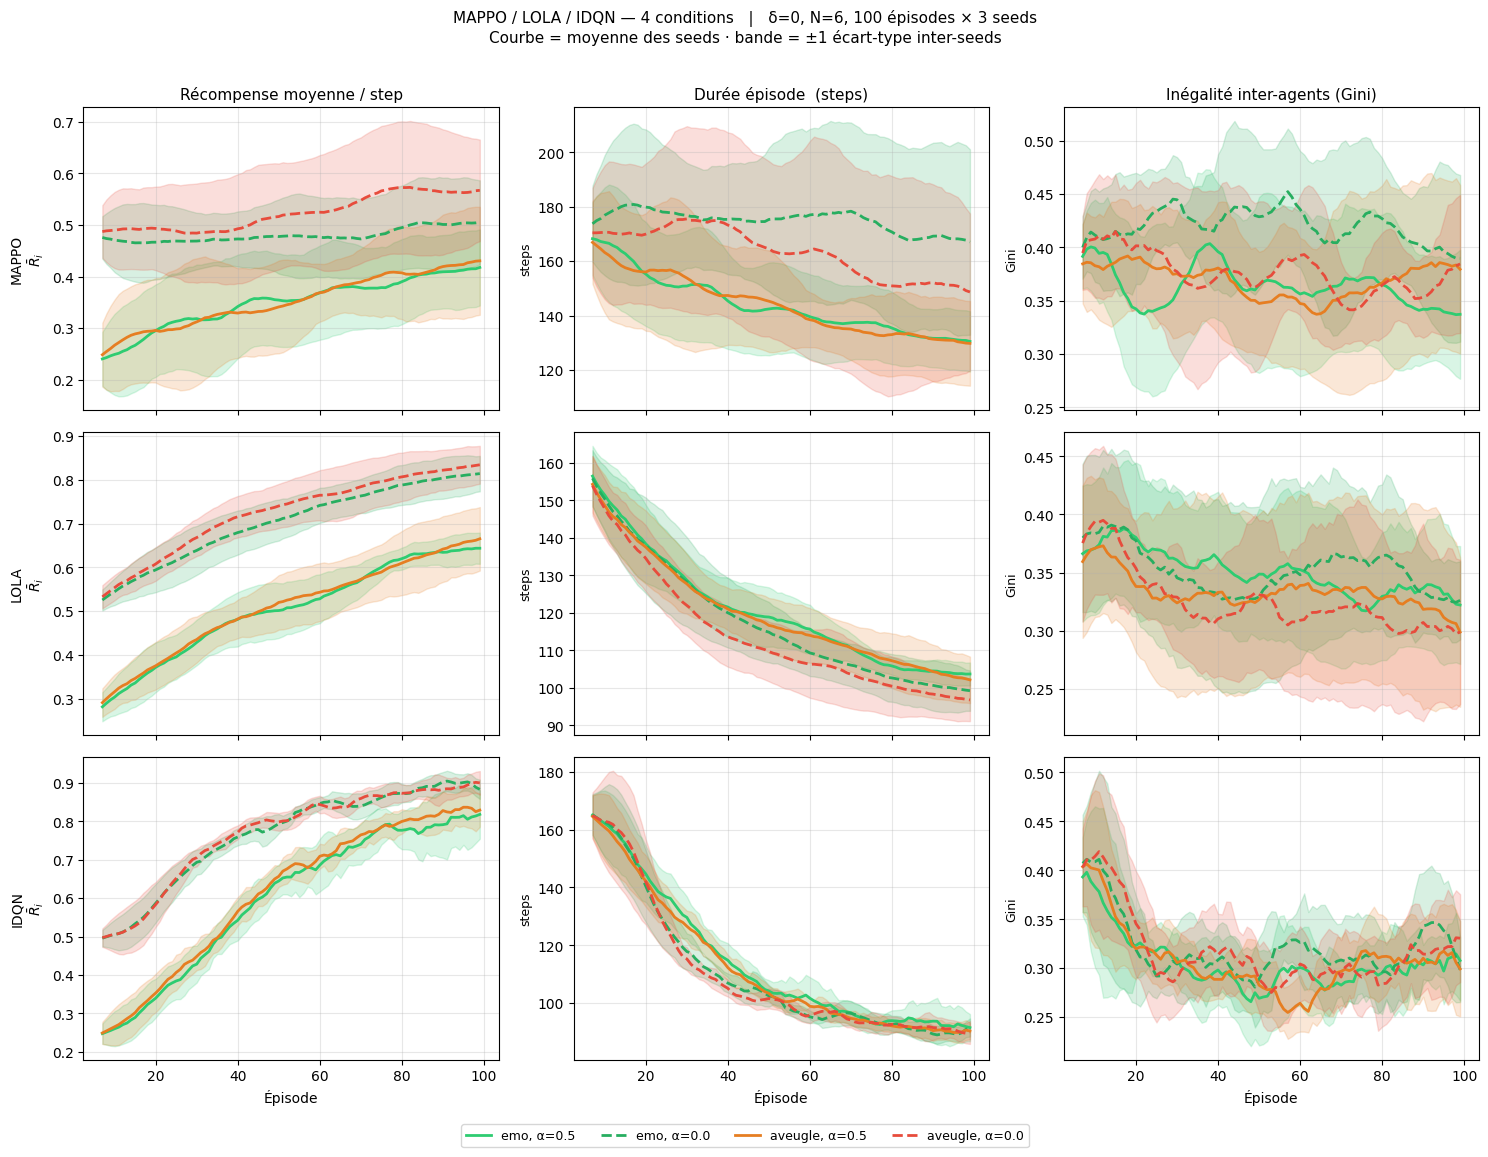


Algo   Condition               R/step    Durée    Gini
─────────────────────────────────────────────────────────
MAPPO  emo, α=0.5             +0.4118±0.0675    131.3   0.341±0.048
MAPPO  emo, α=0.0             +0.5037±0.0850    167.8   0.397±0.061
MAPPO  aveugle, α=0.5         +0.4210±0.0976    131.1   0.380±0.077
MAPPO  aveugle, α=0.0         +0.5659±0.1110    150.6   0.370±0.038

LOLA   emo, α=0.5             +0.6391±0.0304    104.1   0.331±0.051
LOLA   emo, α=0.0             +0.8071±0.0435    100.2   0.333±0.035
LOLA   aveugle, α=0.5         +0.6492±0.0737    103.7   0.314±0.074
LOLA   aveugle, α=0.0         +0.8263±0.0453     97.8   0.300±0.057

IDQN   emo, α=0.5             +0.8052±0.0579     92.5   0.308±0.023
IDQN   emo, α=0.0             +0.8907±0.0175     90.7   0.319±0.023
IDQN   aveugle, α=0.5         +0.8242±0.0356     90.7   0.307±0.033
IDQN   aveugle, α=0.0         +0.8887±0.0150     91.0   0.322±0.024



In [9]:
def smooth(x, w=8):
    return np.convolve(x, np.ones(w)/w, mode='valid')

W = 8
METRICS = [
    ('reward', 'Récompense moyenne / step',    r'$\bar{R}_i$'),
    ('length', 'Durée épisode  (steps)',        'steps'),
    ('gini',   'Inégalité inter-agents (Gini)', 'Gini'),
]

fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=True)

for row, algo in enumerate(ALGOS):
    for col, (key, title, ylabel) in enumerate(METRICS):
        ax = axes[row, col]
        for cond in CONDITIONS:
            label = cond['label']
            st    = COND_STYLE[label]

            # (N_SEEDS, T_smooth) — une courbe lissée par seed
            smoothed = np.stack([
                smooth(np.array(h[key], dtype=float), W)
                for h in results[(algo, label)]
            ])
            mean = smoothed.mean(0)
            std  = smoothed.std(0)
            x    = np.arange(len(mean)) + W - 1

            ax.plot(x, mean, color=st['color'], ls=st['ls'], lw=2, label=label)
            ax.fill_between(x, mean - std, mean + std, color=st['color'], alpha=0.18)

        if row == 0: ax.set_title(title, fontsize=11)
        if col == 0: ax.set_ylabel(f'{algo}\n{ylabel}', fontsize=10)
        else:        ax.set_ylabel(ylabel, fontsize=9)
        if row == 2: ax.set_xlabel('Épisode')
        ax.grid(alpha=0.3)

cond_handles = [plt.Line2D([0],[0], color=COND_STYLE[c['label']]['color'],
                             ls=COND_STYLE[c['label']]['ls'], lw=2, label=c['label'])
                for c in CONDITIONS]
fig.legend(handles=cond_handles, loc='lower center', ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.03), frameon=True)

plt.suptitle(
    f"MAPPO / LOLA / IDQN — 4 conditions   |   δ=0, N=6, {N_EPS} épisodes × {N_SEEDS} seeds\n"
    "Courbe = moyenne des seeds · bande = ±1 écart-type inter-seeds",
    fontsize=11, y=1.01
)
plt.tight_layout()
plt.savefig('mappo_lola_idqn_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Tableau de synthèse ────────────────────────────────────────────────────────
K = 20
print(f"\n{'Algo':6s} {'Condition':20s} {'R/step':>9s} {'Durée':>8s} {'Gini':>7s}")
print('─' * 57)
for algo in ALGOS:
    for cond in CONDITIONS:
        label  = cond['label']
        hists  = results[(algo, label)]
        r_mean = np.mean([np.mean(h['reward'][-K:]) for h in hists])
        l_mean = np.mean([np.mean(h['length'][-K:]) for h in hists])
        g_mean = np.mean([np.mean(h['gini'][-K:]) for h in hists])
        r_std  = np.std( [np.mean(h['reward'][-K:]) for h in hists])
        g_std  = np.std( [np.mean(h['gini'][-K:])   for h in hists])
        print(f"{algo:6s} {label:20s} "
              f"{r_mean:>+9.4f}±{r_std:.4f} "
              f"{l_mean:>8.1f} "
              f"{g_mean:>7.3f}±{g_std:.3f}")
    print()

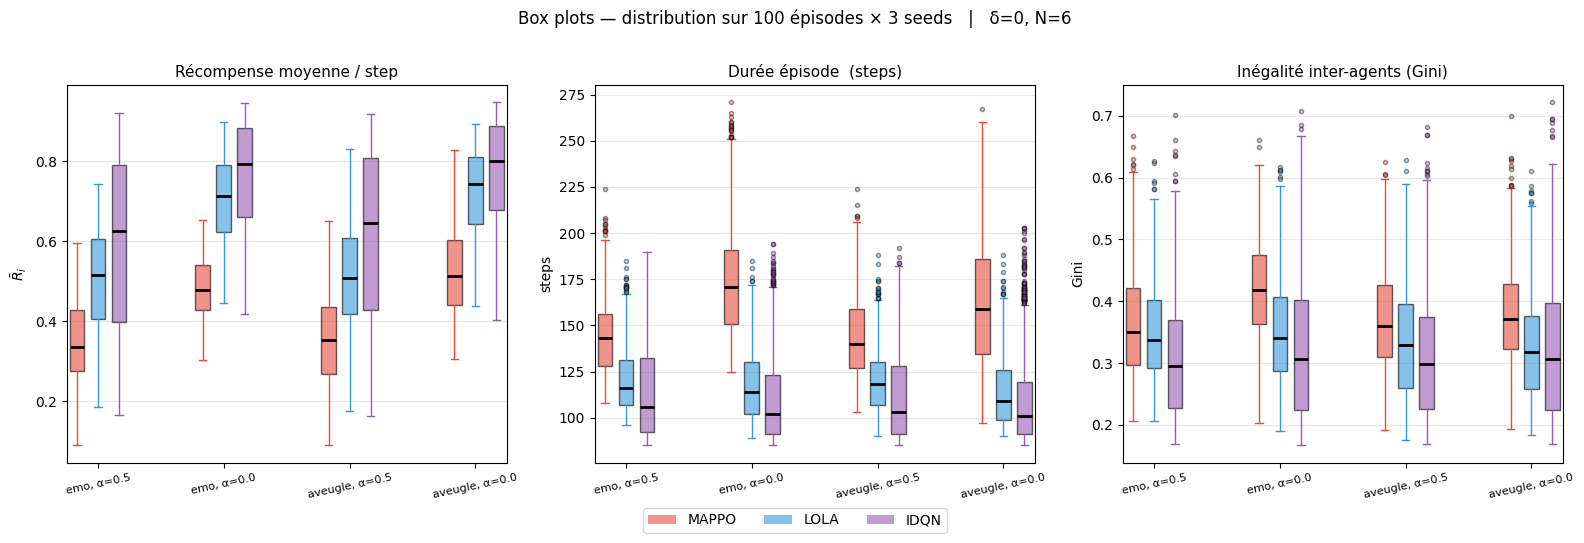

In [10]:
GAP   = 3
W_BOX = 0.7

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for col, (key, title, ylabel) in enumerate(METRICS):
    ax = axes[col]
    tick_pos, tick_labels = [], []

    for g, cond in enumerate(CONDITIONS):
        label = cond['label']
        base  = g * (len(ALGOS) + GAP)

        for a, algo in enumerate(ALGOS):
            pos = base + a
            # Concaténer tous les épisodes de tous les seeds
            data = np.concatenate([h[key] for h in results[(algo, label)]])
            ax.boxplot(data, positions=[pos], widths=W_BOX,
                       patch_artist=True,
                       boxprops=dict(facecolor=ALGO_COLOR[algo], alpha=0.6),
                       medianprops=dict(color='black', linewidth=2),
                       whiskerprops=dict(color=ALGO_COLOR[algo]),
                       capprops=dict(color=ALGO_COLOR[algo]),
                       flierprops=dict(marker='o', markersize=3,
                                       markerfacecolor=ALGO_COLOR[algo], alpha=0.4))

        group_center = base + (len(ALGOS) - 1) / 2
        tick_pos.append(group_center)
        tick_labels.append(label)

    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labels, fontsize=8, rotation=12)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.3)

handles = [plt.Rectangle((0,0), 1, 1, fc=ALGO_COLOR[a], alpha=0.6, label=a) for a in ALGOS]
fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=10,
           bbox_to_anchor=(0.5, -0.05), frameon=True)

plt.suptitle(
    f"Box plots — distribution sur {N_EPS} épisodes × {N_SEEDS} seeds   |   δ=0, N=6",
    fontsize=12, y=1.01
)
plt.tight_layout()
plt.savefig('mappo_lola_idqn_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

## Two-way ANOVA: Empathic Properties & Motivation Effects

Testing whether the ability to see emotions (see_emotions) and empathic motivation (alpha) affect episode length and fairness (Gini coefficient).

In [11]:
from scipy import stats
import pandas as pd

# Extract last K episodes for stability
K_FINAL = 20

# Build dataframe: one row per (algo, condition, seed, episode_in_final_K)
data_records = []
for algo in ALGOS:
    for cond in CONDITIONS:
        see_emotions = cond['see_emotions']
        alpha = cond['alpha']
        label = cond['label']

        for seed_idx, hist in enumerate(results[(algo, label)]):
            # Last K episodes for episode length and gini
            final_lengths = hist['length'][-K_FINAL:]
            final_ginis   = hist['gini'][-K_FINAL:]

            for ep_idx, (length, gini) in enumerate(zip(final_lengths, final_ginis)):
                data_records.append({
                    'algo': algo,
                    'see_emotions': see_emotions,
                    'alpha': alpha,
                    'seed': seed_idx,
                    'episode': ep_idx,
                    'length': length,
                    'gini': gini,
                })

df = pd.DataFrame(data_records)
print(f"Dataset shape: {df.shape}")
print(f"Algorithms: {df['algo'].unique()}")
print(f"See emotions: {df['see_emotions'].unique()}")
print(f"Alpha values: {df['alpha'].unique()}")
print(f"\nFirst few rows:")
print(df.head())

Dataset shape: (2400, 7)
Algorithms: ['MAPPO' 'LOLA' 'IDQN']
See emotions: [ True False]
Alpha values: [0.5 0. ]

First few rows:
    algo  see_emotions  alpha  seed  episode  length      gini
0  MAPPO          True    0.5     0        0     123  0.452271
1  MAPPO          True    0.5     0        1     123  0.417192
2  MAPPO          True    0.5     0        2     122  0.484314
3  MAPPO          True    0.5     0        3     128  0.430450
4  MAPPO          True    0.5     0        4     122  0.455870


In [12]:
def compute_anova_and_effect_size(df_subset, dep_var):
    """Compute two-way ANOVA and eta-squared effect sizes."""
    from scipy.stats import f_oneway

    # Main effects
    groups_see_emotions_true = df_subset[df_subset['see_emotions'] == True][dep_var].values
    groups_see_emotions_false = df_subset[df_subset['see_emotions'] == False][dep_var].values

    groups_alpha_0_5 = df_subset[df_subset['alpha'] == 0.5][dep_var].values
    groups_alpha_0_0 = df_subset[df_subset['alpha'] == 0.0][dep_var].values

    # One-way F-tests (simplified approximation)
    f_see_emotions, p_see_emotions = f_oneway(groups_see_emotions_true, groups_see_emotions_false)
    f_alpha, p_alpha = f_oneway(groups_alpha_0_5, groups_alpha_0_0)

    # Effect sizes (eta-squared approximation)
    grand_mean = df_subset[dep_var].mean()
    ss_total = ((df_subset[dep_var] - grand_mean) ** 2).sum()

    # Main effect 1: see_emotions
    group_means_se = df_subset.groupby('see_emotions')[dep_var].mean()
    group_counts_se = df_subset.groupby('see_emotions')[dep_var].count()
    ss_se = (group_means_se - grand_mean).pow(2) * group_counts_se
    eta2_see_emotions = ss_se.sum() / ss_total

    # Main effect 2: alpha
    group_means_alpha = df_subset.groupby('alpha')[dep_var].mean()
    group_counts_alpha = df_subset.groupby('alpha')[dep_var].count()
    ss_alpha = (group_means_alpha - grand_mean).pow(2) * group_counts_alpha
    eta2_alpha = ss_alpha.sum() / ss_total

    return {
        'f_see_emotions': f_see_emotions,
        'p_see_emotions': p_see_emotions,
        'eta2_see_emotions': eta2_see_emotions,
        'f_alpha': f_alpha,
        'p_alpha': p_alpha,
        'eta2_alpha': eta2_alpha,
    }

print("=" * 80)
print("TWO-WAY ANOVA: Episode Length")
print("=" * 80)

for algo in ALGOS:
    df_algo = df[df['algo'] == algo]
    stats_length = compute_anova_and_effect_size(df_algo, 'length')

    print(f"\n{algo}:")
    print(f"  see_emotions: F = {stats_length['f_see_emotions']:7.2f}, "
          f"p = {stats_length['p_see_emotions']:.4f}, η² = {stats_length['eta2_see_emotions']:.4f}")
    print(f"  alpha:        F = {stats_length['f_alpha']:7.2f}, "
          f"p = {stats_length['p_alpha']:.4f}, η² = {stats_length['eta2_alpha']:.4f}")

print("\n" + "=" * 80)
print("TWO-WAY ANOVA: Fairness (Gini)")
print("=" * 80)

for algo in ALGOS:
    df_algo = df[df['algo'] == algo]
    stats_gini = compute_anova_and_effect_size(df_algo, 'gini')

    print(f"\n{algo}:")
    print(f"  see_emotions: F = {stats_gini['f_see_emotions']:7.2f}, "
          f"p = {stats_gini['p_see_emotions']:.4f}, η² = {stats_gini['eta2_see_emotions']:.4f}")
    print(f"  alpha:        F = {stats_gini['f_alpha']:7.2f}, "
          f"p = {stats_gini['p_alpha']:.4f}, η² = {stats_gini['eta2_alpha']:.4f}")

TWO-WAY ANOVA: Episode Length

MAPPO:
  see_emotions: F =   16.95, p = 0.0000, η² = 0.0208
  alpha:        F =  214.61, p = 0.0000, η² = 0.2119

LOLA:
  see_emotions: F =    9.40, p = 0.0022, η² = 0.0116
  alpha:        F =  124.56, p = 0.0000, η² = 0.1350

IDQN:
  see_emotions: F =    1.60, p = 0.2068, η² = 0.0020
  alpha:        F =    1.64, p = 0.2007, η² = 0.0021

TWO-WAY ANOVA: Fairness (Gini)

MAPPO:
  see_emotions: F =    1.04, p = 0.3079, η² = 0.0013
  alpha:        F =   18.35, p = 0.0000, η² = 0.0225

LOLA:
  see_emotions: F =   20.67, p = 0.0000, η² = 0.0252
  alpha:        F =    1.21, p = 0.2721, η² = 0.0015

IDQN:
  see_emotions: F =    0.01, p = 0.9334, η² = 0.0000
  alpha:        F =    2.57, p = 0.1092, η² = 0.0032


### ANOVA Visualizations

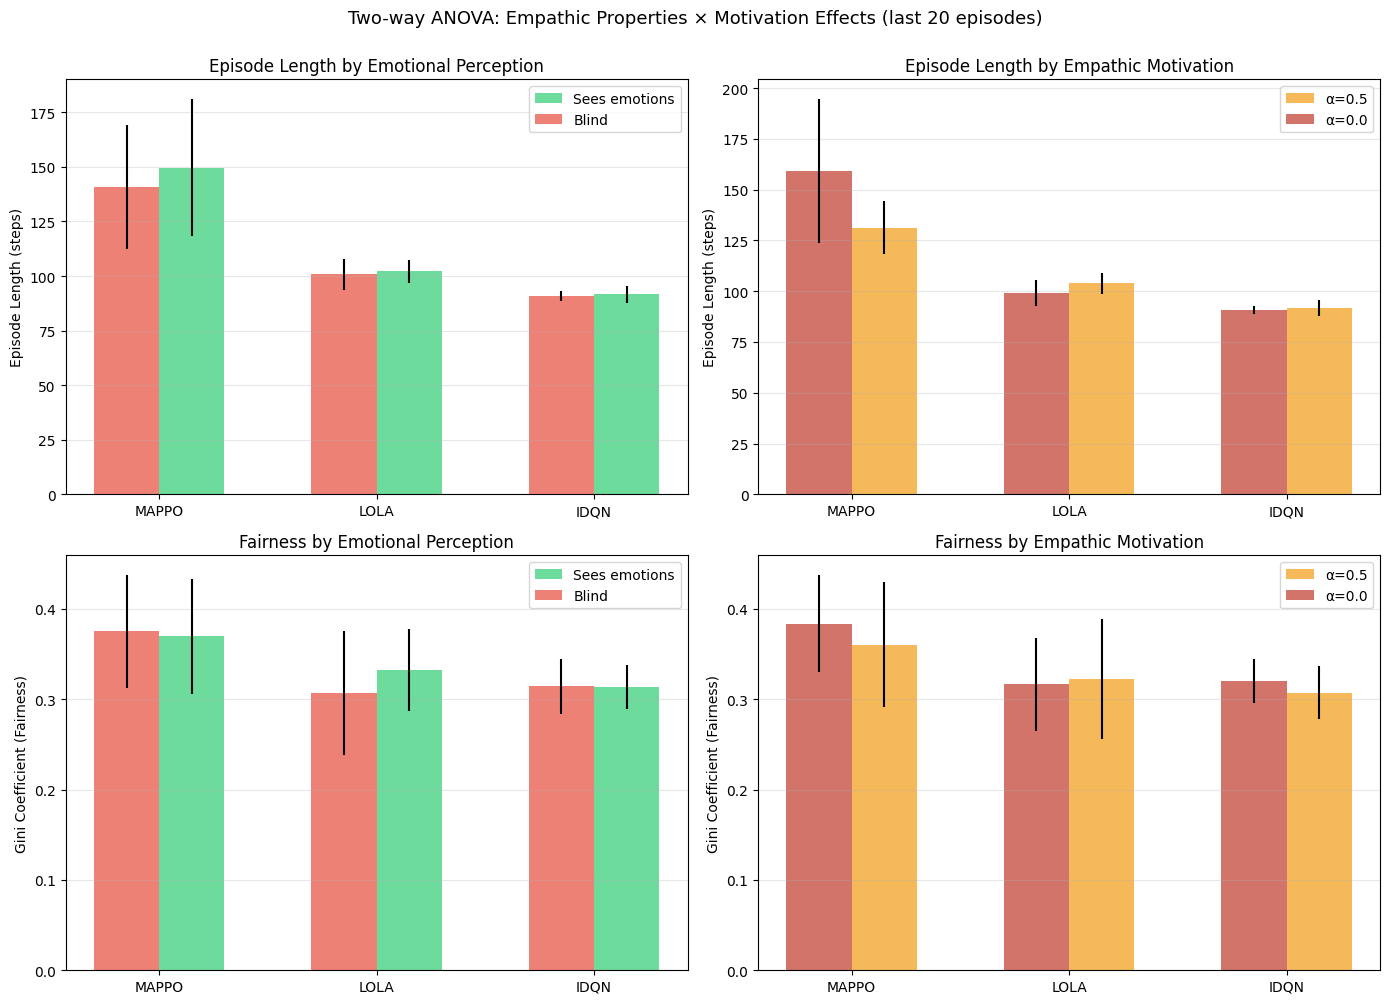

: 

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Prepare data: average over seeds for each condition
summary_data = []
for algo in ALGOS:
    for cond in CONDITIONS:
        label = cond['label']
        see_emotions = cond['see_emotions']
        alpha = cond['alpha']

        hists = results[(algo, label)]
        final_lengths = [np.mean(h['length'][-K_FINAL:]) for h in hists]
        final_ginis   = [np.mean(h['gini'][-K_FINAL:]) for h in hists]

        for length, gini in zip(final_lengths, final_ginis):
            summary_data.append({
                'algo': algo,
                'see_emotions': 'Sees emotions' if see_emotions else 'Blind',
                'alpha': f'α={alpha}',
                'cond_label': label,
                'length': length,
                'gini': gini,
            })

df_summary = pd.DataFrame(summary_data)

# 1. Episode Length: see_emotions effect
ax = axes[0, 0]
for algo in ALGOS:
    for see_emo_label, see_emo_bool in [('Sees emotions', True), ('Blind', False)]:
        subset = df_summary[(df_summary['algo'] == algo) & (df_summary['see_emotions'] == see_emo_label)]
        if len(subset) > 0:
            mean_length = subset['length'].mean()
            std_length = subset['length'].std()
            x_pos = list(ALGOS).index(algo) + (0.15 if see_emo_bool else -0.15)
            color = '#2ecc71' if see_emo_bool else '#e74c3c'
            ax.bar(x_pos, mean_length, width=0.3, color=color, alpha=0.7,
                   label=see_emo_label if algo == ALGOS[0] else '')
            ax.errorbar(x_pos, mean_length, yerr=std_length, fmt='none', color='black', elinewidth=1.5)

ax.set_xticks(range(len(ALGOS)))
ax.set_xticklabels(ALGOS)
ax.set_ylabel('Episode Length (steps)')
ax.set_title('Episode Length by Emotional Perception')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# 2. Episode Length: alpha effect
ax = axes[0, 1]
for algo in ALGOS:
    for alpha_label, alpha_val in [('α=0.5', 0.5), ('α=0.0', 0.0)]:
        subset = df_summary[(df_summary['algo'] == algo) & (df_summary['alpha'] == alpha_label)]
        if len(subset) > 0:
            mean_length = subset['length'].mean()
            std_length = subset['length'].std()
            x_pos = list(ALGOS).index(algo) + (0.15 if alpha_val == 0.5 else -0.15)
            color = '#f39c12' if alpha_val == 0.5 else '#c0392b'
            ax.bar(x_pos, mean_length, width=0.3, color=color, alpha=0.7,
                   label=alpha_label if algo == ALGOS[0] else '')
            ax.errorbar(x_pos, mean_length, yerr=std_length, fmt='none', color='black', elinewidth=1.5)

ax.set_xticks(range(len(ALGOS)))
ax.set_xticklabels(ALGOS)
ax.set_ylabel('Episode Length (steps)')
ax.set_title('Episode Length by Empathic Motivation')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# 3. Fairness (Gini): see_emotions effect
ax = axes[1, 0]
for algo in ALGOS:
    for see_emo_label, see_emo_bool in [('Sees emotions', True), ('Blind', False)]:
        subset = df_summary[(df_summary['algo'] == algo) & (df_summary['see_emotions'] == see_emo_label)]
        if len(subset) > 0:
            mean_gini = subset['gini'].mean()
            std_gini = subset['gini'].std()
            x_pos = list(ALGOS).index(algo) + (0.15 if see_emo_bool else -0.15)
            color = '#2ecc71' if see_emo_bool else '#e74c3c'
            ax.bar(x_pos, mean_gini, width=0.3, color=color, alpha=0.7,
                   label=see_emo_label if algo == ALGOS[0] else '')
            ax.errorbar(x_pos, mean_gini, yerr=std_gini, fmt='none', color='black', elinewidth=1.5)

ax.set_xticks(range(len(ALGOS)))
ax.set_xticklabels(ALGOS)
ax.set_ylabel('Gini Coefficient (Fairness)')
ax.set_title('Fairness by Emotional Perception')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# 4. Fairness (Gini): alpha effect
ax = axes[1, 1]
for algo in ALGOS:
    for alpha_label, alpha_val in [('α=0.5', 0.5), ('α=0.0', 0.0)]:
        subset = df_summary[(df_summary['algo'] == algo) & (df_summary['alpha'] == alpha_label)]
        if len(subset) > 0:
            mean_gini = subset['gini'].mean()
            std_gini = subset['gini'].std()
            x_pos = list(ALGOS).index(algo) + (0.15 if alpha_val == 0.5 else -0.15)
            color = '#f39c12' if alpha_val == 0.5 else '#c0392b'
            ax.bar(x_pos, mean_gini, width=0.3, color=color, alpha=0.7,
                   label=alpha_label if algo == ALGOS[0] else '')
            ax.errorbar(x_pos, mean_gini, yerr=std_gini, fmt='none', color='black', elinewidth=1.5)

ax.set_xticks(range(len(ALGOS)))
ax.set_xticklabels(ALGOS)
ax.set_ylabel('Gini Coefficient (Fairness)')
ax.set_title('Fairness by Empathic Motivation')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.suptitle(f'Two-way ANOVA: Empathic Properties × Motivation Effects (last {K_FINAL} episodes)',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('anova_empathy_effects.png', dpi=150, bbox_inches='tight')
plt.show()